# ¿Perros o gatos? Enrique Herranz Acosta

## Introducción
En el siguiente trabajo, la tarea es entrenar un modelo para que sepa clasificar si una imagen corresponde a un perro o a un gato. El concurso me proporciona el conjunto de datos de entrenamiento,test y otros suplementarios. Primero, vamos a importar los módulos requeridos y establecer el tamaño de imágenes y de tanda.

Para resolver este problema no empezaré de 0, sino que usaré una red preentrenada con ImageNet. Aprovecharemos características que la red ya reconoce (bordes y texturas) par centrarnos en la clasificación específica del problema.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

competition = "u-tad-26-ai-cat-or-dog"
seed = 42           #fija la semilla para replicar resultados
image_size = (224, 224)
batch_size = 32     #Con lotes de 32, cada época tiene unos 625 pasos


tf.keras.utils.set_random_seed(seed)

# Carga de datos

A continuación, cargamos los datos de entrenamiento y los suplementarios.
Cabe destacar que vamos a usar el 80% de las imágenes para entrenar y el 20% para comprobar. Las de entrenamiento nos ayudarán a ajustar los pesos, y el de validación evaluará la capacidad del modelo.

El conjunto suplementario no es usado durante el entrenamiento; sirve para comprobar el desempeño del modelo en un set de datos que no ha tocado

In [2]:
train_dir = f"/kaggle/input/competitions/{competition}/train/train"
supp_dir = f"/kaggle/input/competitions/{competition}/supplementary_data/supplementary_data"

train_ds, val_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="both",
    seed=seed,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
)

Found 25000 files belonging to 2 classes.
Using 20000 files for training.
Using 5000 files for validation.


In [3]:
class_names = train_ds.class_names

supplementary_ds = keras.utils.image_dataset_from_directory(
    supp_dir,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=False,
)

Found 300 files belonging to 2 classes.


La opción siguiente, el prefetch, permite preparar los próximos lotes mientras se procesa la actual, para reducir el tiempo de espera

In [4]:
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
supplementary_ds = supplementary_ds.prefetch(tf.data.AUTOTUNE)

Para mejorar la capacidad de reconocimiento de datos, se han aplciado una serie de transformaciones al conjunto durante el entrenamiento (volteo,rotar,zoom,contraste). Esto hace que el modelo sea más robusto, preparándose para distitnas posibles variaciones, en vez de simplemente memorizar.

In [5]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

En un principio usé el modelo ResNetV2, pero para lograr mejores resultados he pasado al modelo EfficientNetV2. Ya sabe mirar imágenes (bordes y partes), así que partimos de una buena base.Este modelo usa pesos de ImageNet, pero se le quita su capa final porque no se corresponde a las 2 categorías que se busca clasificar (include_top=False). Congelamos todas las capas, aunque más adelante descongelaremos algunas

In [6]:
base_model = keras.applications.EfficientNetV2S(
    weights="imagenet",
    include_top=False, #Se quita la capa final
    input_shape=image_size + (3,),
    include_preprocessing=True,
)
base_model.trainable = False #Por ahora dejamos sus pesos "congelados"

inputs = keras.Input(shape=image_size + (3,))
x = data_augmentation(inputs)
x = base_model(x, training=False)      # entrada en [0, 255], sin Rescaling
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)             # cuando entrena apaga 3/10 de sus neuronas, ayudando a reducir el overfitting
outputs = layers.Dense(2, activation="softmax")(x) # es la nueva cabeza, que contempla 2 posibilidades

model = keras.Model(inputs, outputs)

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


# Variante Final (Fine-tuning)

En una primera fase, entrené solo la cabeza del modelo, pero esta nueva versión mejora la precisión


Vamos a ver ahora si el modelo es efectivo al "descongelar" las últimas capas de EfficientNetV2, para que las capas más profundas se especialicen en nuestro problema concreto. No descongelamos todas porque no conviene cambiar los pesos de las primeras, que son muy generales (bordes,texturas), ni tampoco las capas de BatchNormalization. Usaremos EarlyStopping con paciencia de 3 épocas para que deje de entrenarse si después de ciertas épocas, el val_loss no mejora,restore_best_weights=True conserva esos mejores pesos. ReduceLROnPlateau de 2 épocas sirve para reducir el learning rate si el val_loss no mejora. El learning rate es muy bajo para no modificar demasiado los pesos.

In [7]:
base_model.trainable = True
for layer in base_model.layers[:-120]:
    layer.trainable = False
    
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_layers = sum(1 for layer in base_model.layers if layer.trainable)
print(f"Capas totales: {len(base_model.layers)}")
print(f"Capas entrenables: {trainable_layers}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

reduce_lr_ft = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping_ft, reduce_lr_ft],
)
val_loss_final, val_accuracy_final = model.evaluate(val_ds, verbose=0)
supp_loss_final, supp_accuracy_final = model.evaluate(supplementary_ds, verbose=0)

Capas totales: 513
Capas entrenables: 96
Epoch 1/15


E0000 00:00:1794507033.456086      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetv2-s_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


625/625 ━━━━━━━━━━━━━━━━━━━━ 170s 229ms/step - accuracy: 0.9826 - loss: 0.0597 - val_accuracy: 0.9944 - val_loss: 0.0171 - learning_rate: 2.0000e-05
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 141s 225ms/step - accuracy: 0.9934 - loss: 0.0201 - val_accuracy: 0.9954 - val_loss: 0.0152 - learning_rate: 2.0000e-05
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 224ms/step - accuracy: 0.9947 - loss: 0.0163 - val_accuracy: 0.9946 - val_loss: 0.0141 - learning_rate: 2.0000e-05
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 224ms/step - accuracy: 0.9961 - loss: 0.0115 - val_accuracy: 0.9952 - val_loss: 0.0152 - learning_rate: 2.0000e-05
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 224ms/step - accuracy: 0.9974 - loss: 0.0075 - val_accuracy: 0.9956 - val_loss: 0.0163 - learning_rate: 2.0000e-05
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 224ms/step - accuracy: 0.9976 - loss: 0.0065 - val_accuracy: 0.9958 - val_loss: 0.0165 - learning_rate: 4.0000e-06


# Observamos los resultados

Para ello utilizaremos dos métricas:

Accuracy: proporción de imágenes clasificadas correctamente.

Loss: valor de la función de pérdida.

Es importante analizar ambas métricas conjuntamente. Una precisión elevada no implica necesariamente que las predicciones sean buenas, mientras que la pérdida también permite ver la calidad de las predicciones.

In [8]:
print("\n=== RESULTADOS FINALES ===")
print(f"Modelo: EfficientNetV2 (fine-tuning)")
print(f"Accuracy validación:    {val_accuracy_final:.4f}")
print(f"Loss validación:        {val_loss_final:.4f}")
print(f"Accuracy suplementario: {supp_accuracy_final:.4f}")
print(f"Loss suplementario:     {supp_loss_final:.4f}")
print(f"Épocas fine-tuning:      {len(history_ft.history['loss'])}")


=== RESULTADOS FINALES ===
Modelo: EfficientNetV2 (fine-tuning)
Accuracy validación:    0.9946
Loss validación:        0.0141
Accuracy suplementario: 0.8500
Loss suplementario:     0.4816
Épocas fine-tuning:      6


El conjunto suplementario obtiene una accuracy considerablemente menor, del 84,7%. Esto hace ver que el modelo puede empeorar su precisión, según el modelo de datos que se utilice


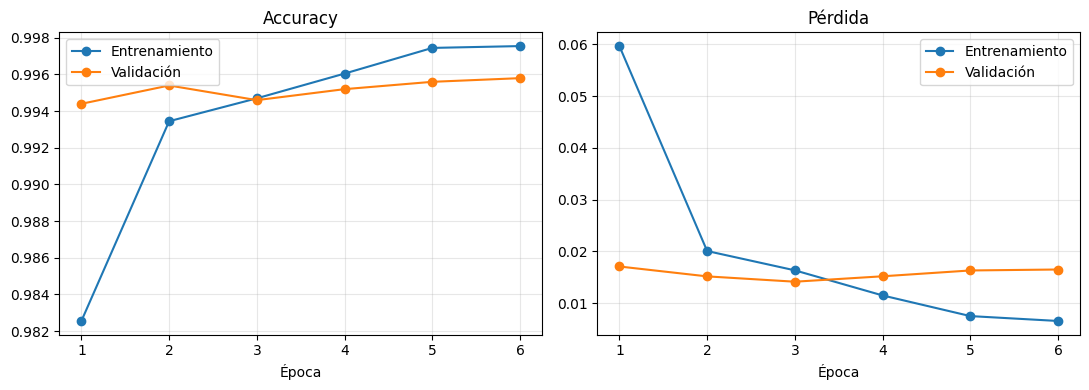

In [9]:
# Curvas del fine-tuning
epocas = range(1, len(history_ft.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, tr, va, title in [
    (axes[0], history_ft.history["accuracy"], history_ft.history["val_accuracy"], "Accuracy"),
    (axes[1], history_ft.history["loss"], history_ft.history["val_loss"], "Pérdida"),
]:
    ax.plot(epocas, tr, marker="o", label="Entrenamiento")
    ax.plot(epocas, va, marker="o", label="Validación")
    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.set_xticks(list(epocas))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

El modelo con fine-tuning alcanza su mejor validación en la época 3. A partir de ahí la pérdida de entrenamiento disminuye, pero la de validación aumenta un poco, indicando ligero overfitting, por lo que EarlyStopping actúa para detenerse en la época 6 y conservar los mejores pesos. La diferencia entre entrenamiento y validación durante las primeras épocas se debe a que el modelo se entrena con los datos variados (torcidos,rotados,contraste,zoom...) mientras que los de validación no.

# Guardamos el modelo y probamos el test

Una vez guardado, cargamos el conjunto de datos de test y usamos nuestro modelo para clasificar sus imágenes

In [10]:
model.save("efficientnetv2s_finetuning_perros_gatos.keras")

folder_path = f"/kaggle/input/competitions/{competition}/test/test"

predictions_dict = {}

for img in os.listdir(folder_path):
    img = os.path.join(folder_path, img)
    
    # save the image name
    file_name = img.split('/')[-1]
    file_no_extension = file_name.split('.')[0]
    
    img = keras.utils.load_img(img, target_size=image_size)
    img_array = keras.utils.img_to_array(img)
    img_array = keras.ops.expand_dims(img_array, 0)
    prediction = model.predict(img_array, verbose=None)
    label = np.argmax(prediction)

    # save the predictions to a dictionary
    predictions_dict[int(file_no_extension)] = label

In [11]:
submission = pd.DataFrame(predictions_dict.items(), columns=["id", "label"]).sort_values(by='id', ascending=True)
submission.to_csv('submission.csv',index=False)

# print numbers of each class label
submission["label"].value_counts()

label
0    614
1    453
Name: count, dtype: int64

El archivo muestra aproximadamente 6/10 imágenes clasificadas en la clase 0 y 4/10 en la clase 1.



Como la distribución real de imágenes es desconocida, no podemos suponer si estos datos son buenos o malos

# Conclusión

Ha sido útil usar EfficientNetV2, porque me ha ahorrado entrenar una red desde 0, porque esta ya conocía características generales. Descongelar las últimas capas además de la cabeza (fine-tuning) ha mejorado la precisión respecto a la primera variante, en la que las capas estaban congeladas y yo entranaba únicamente la nueva cabeza.
Se ha visto en la gráfica que tras el fine-tuning, la pérdida de validación ha comenzado a aumentar tras haber bajado en un principio, señal de overfitting, por eso ha sido fundamental usar el early stopping, que evita usar estos pesos empeorados.

Hay que destacar que la precisión de los datos suplementarios es significativamente menor; pasamos de un 99,6 a un 84,7. Esto demuestra que el modelo no es capaz de generalizar una clasificación efectiva para un conjunto de datos cualquiera, a pesar de que mis resultados de validación sean excelentes.